# 20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed: tuned



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "tuned" / "by_family" / '20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.578855,0.108002,15
1,DAGMA_Linear,0.445591,0.126224,15
2,DAGMA_Nonlinear,0.435175,0.071107,15
3,DAS,0.459479,0.120389,15
4,DirectLiNGAM,0.400395,0.090428,15
5,FCI,0.327422,0.129054,15
6,GES,0.446278,0.137992,15
7,GOLEM,0.397449,0.107916,15
8,GRaSP,0.465459,0.127769,15
9,GraNDAG,0.421302,0.186879,15


,model,mean,std,size
0,AVICI,17.000000,4.035556,15
1,DAGMA_Linear,19.866667,4.290632,15
2,DAGMA_Nonlinear,20.333333,3.354883,15
3,DAS,25.866667,8.382521,15
4,DirectLiNGAM,22.200000,4.345770,15
5,FCI,22.680000,3.130313,15
6,GES,23.000000,4.780914,15
7,GOLEM,21.600000,4.762952,15
8,GRaSP,22.426667,4.653642,15
9,GraNDAG,19.666667,4.303930,15


,model,mean,std,size
0,AVICI,0.747022,0.158774,15
1,DAGMA_Linear,0.547660,0.172122,15
2,DAGMA_Nonlinear,0.642697,0.123956,15
3,DAS,0.425514,0.124267,15
4,DirectLiNGAM,0.457529,0.114883,15
5,FCI,0.756049,0.175842,15
6,GES,0.574394,0.164272,15
7,GOLEM,0.477051,0.118823,15
8,GRaSP,0.609458,0.157124,15
9,GraNDAG,0.649551,0.189010,15


,model,mean,std,size
0,AVICI,0.481237,0.103380,15
1,DAGMA_Linear,0.383759,0.120930,15
2,DAGMA_Nonlinear,0.338887,0.072597,15
3,DAS,0.512525,0.131963,15
4,DirectLiNGAM,0.364020,0.092483,15
5,FCI,0.222526,0.106091,15
6,GES,0.381091,0.141145,15
7,GOLEM,0.346756,0.104134,15
8,GRaSP,0.390830,0.129822,15
9,GraNDAG,0.333626,0.181503,15


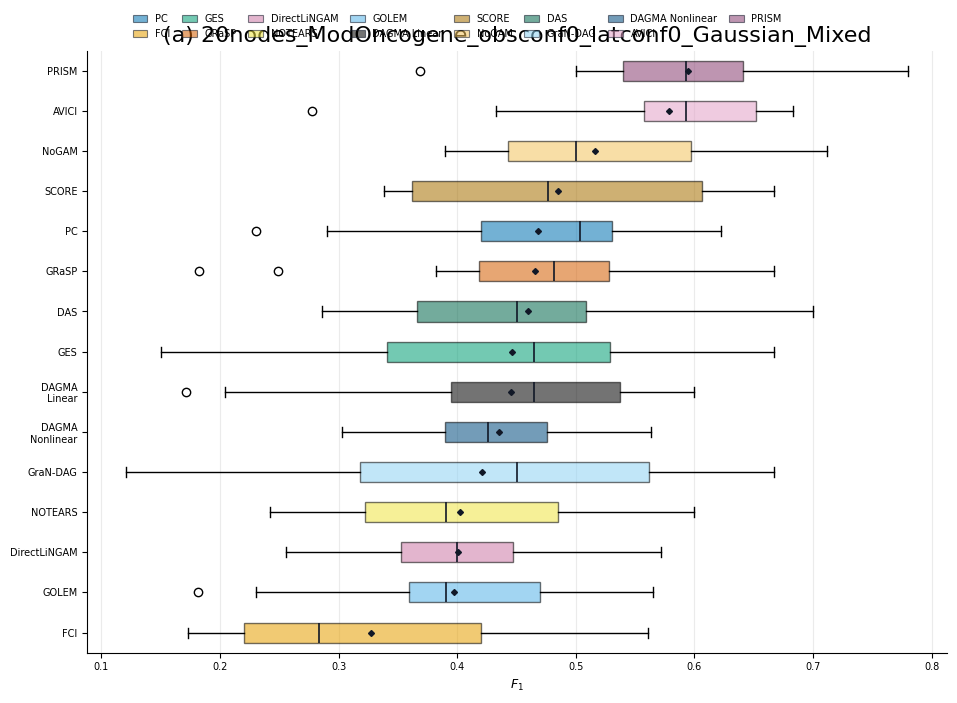

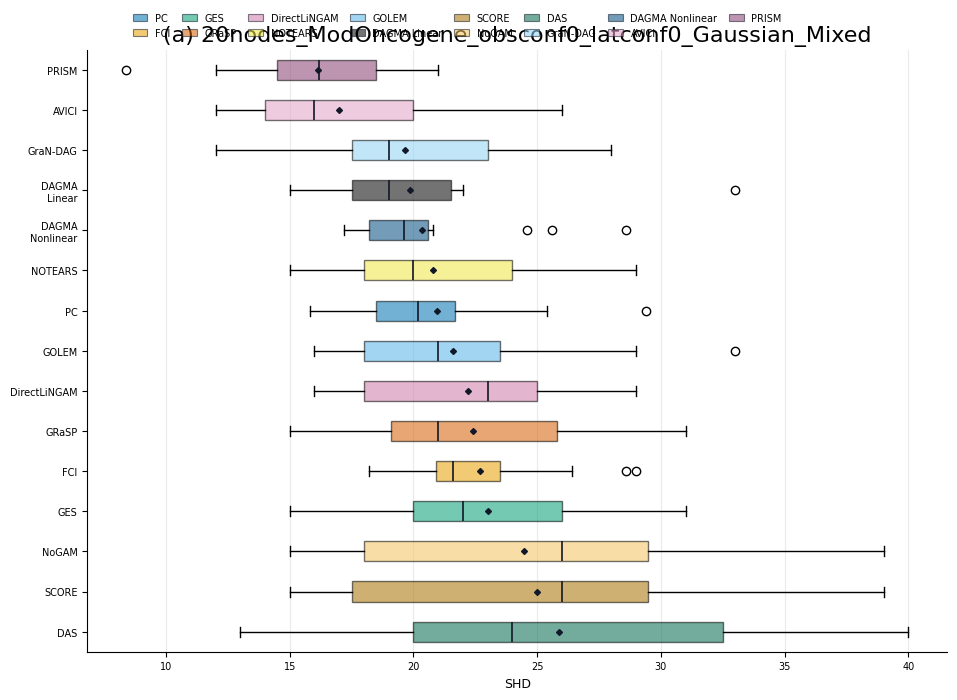

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.121212
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.068111
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.186047
9,19,GraNDAG,0.000000


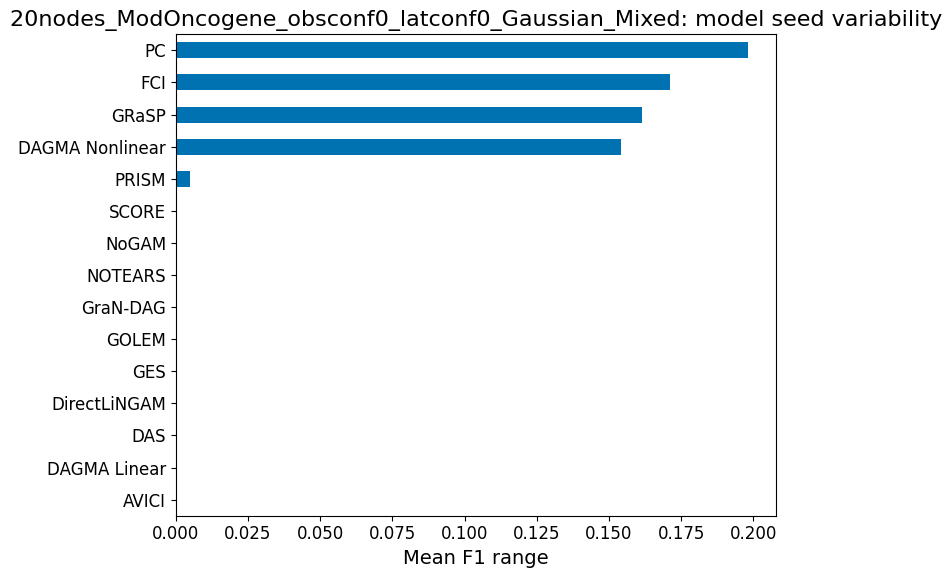

,model_seed,model,f1_range
0,0,AVICI,0.405149
1,0,DAGMA_Linear,0.428571
2,0,DAGMA_Nonlinear,0.311111
3,0,DAS,0.414286
4,0,DirectLiNGAM,0.316109
5,0,FCI,0.549407
6,0,GES,0.516667
7,0,GOLEM,0.383399
8,0,GRaSP,0.571429
9,0,GraNDAG,0.545455


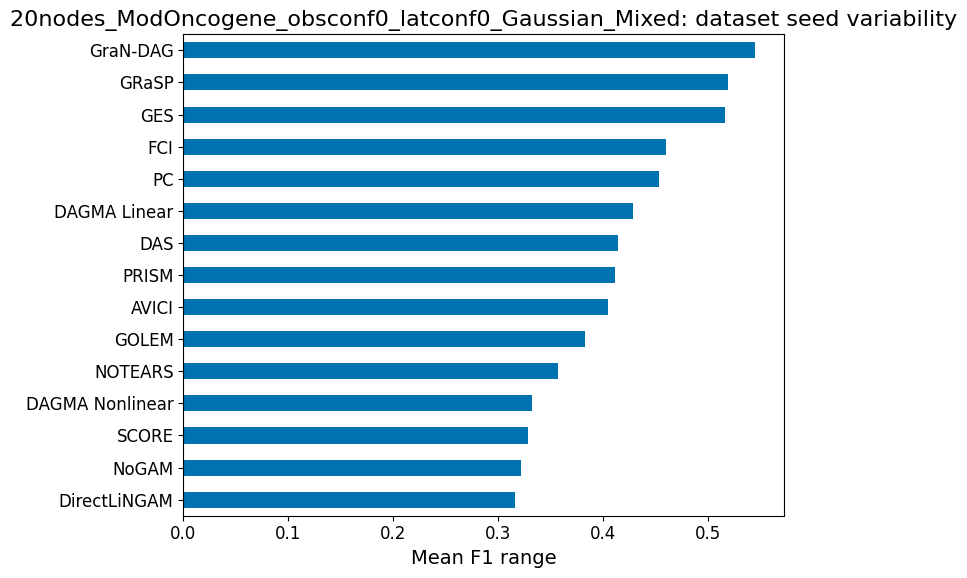

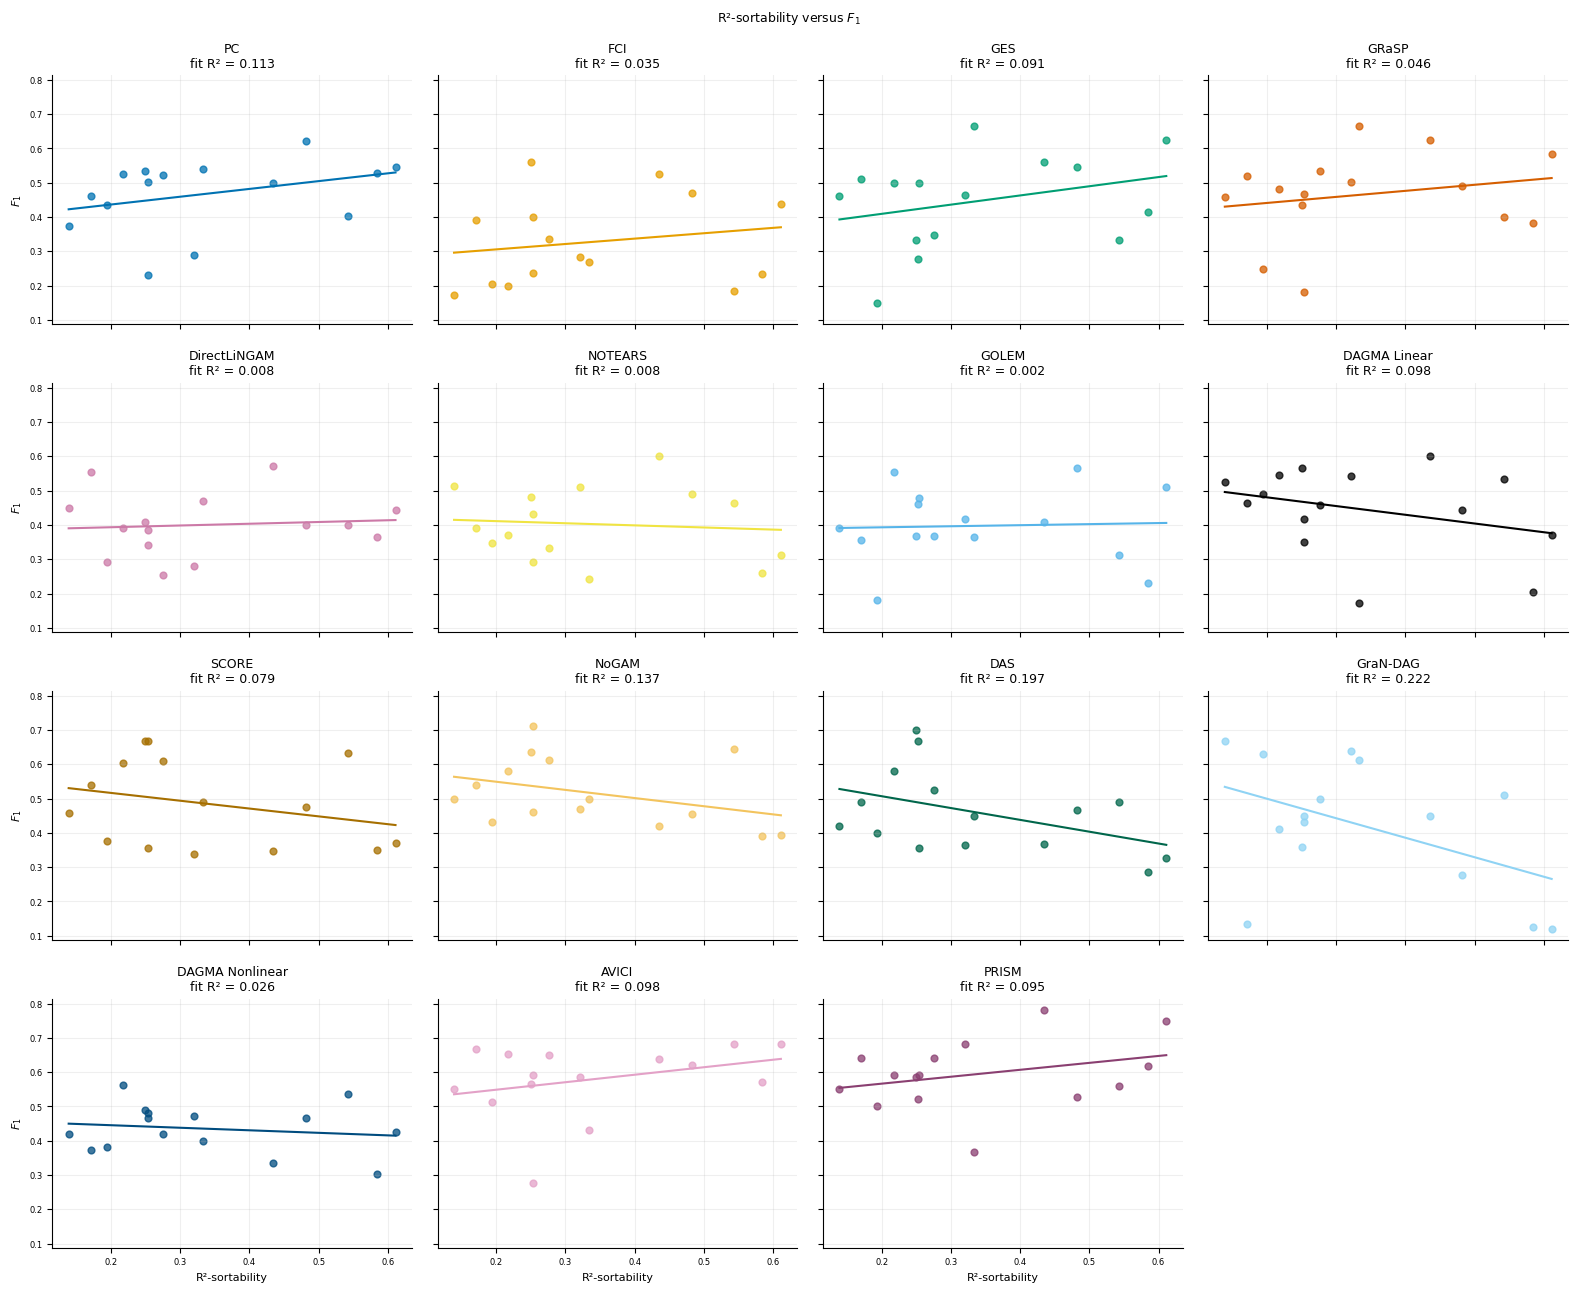

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,0.666667,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,0.465116,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
2,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,0.373396,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
3,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,0.489796,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
4,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,0.553191,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
5,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,0.390354,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
6,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,0.511628,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
7,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,0.355556,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
8,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,0.520930,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
9,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,0.133333,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,19,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,47,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.321739,0.139130,115,37,0,16,0,20,2000
2,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,50,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.280000,0.250000,100,28,0,25,0,20,2000
3,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,52,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.500000,0.482143,56,28,0,27,0,20,2000
4,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,71,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.478261,0.217391,46,22,0,10,0,20,2000
5,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,75,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.391304,0.434783,92,36,0,40,0,20,2000
6,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,77,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.457143,0.542857,70,32,0,38,0,20,2000
7,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,102,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.620690,0.275862,58,36,0,16,0,20,2000
8,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,125,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.566038,0.320755,53,30,0,17,0,20,2000
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,158,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.417910,0.253731,67,28,0,17,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.313699,0.098407,0.218570,0.505082,0.254876,0.335714,0.221212
1,DAGMA_Linear,15,-0.312428,0.097611,-0.254413,0.531461,0.256909,-0.321429,0.242719
2,DAGMA_Nonlinear,15,-0.161381,0.026044,-0.074030,0.460162,0.565569,-0.089286,0.751673
3,DAS,15,-0.444042,0.197173,-0.344871,0.575882,0.097291,-0.432143,0.107693
4,DirectLiNGAM,15,0.087253,0.007613,0.050902,0.383214,0.757167,0.005362,0.984869
5,FCI,15,0.188413,0.035499,0.156865,0.274476,0.501280,0.260714,0.347979
6,GES,15,0.301168,0.090702,0.268107,0.355785,0.275359,0.338104,0.217735
7,GOLEM,15,0.044563,0.001986,0.031024,0.386978,0.874697,0.109026,0.698919
8,GRaSP,15,0.214127,0.045850,0.176499,0.405886,0.443488,0.260714,0.347979
9,GraNDAG,15,-0.471567,0.222375,-0.568525,0.613194,0.075973,-0.348526,0.202980


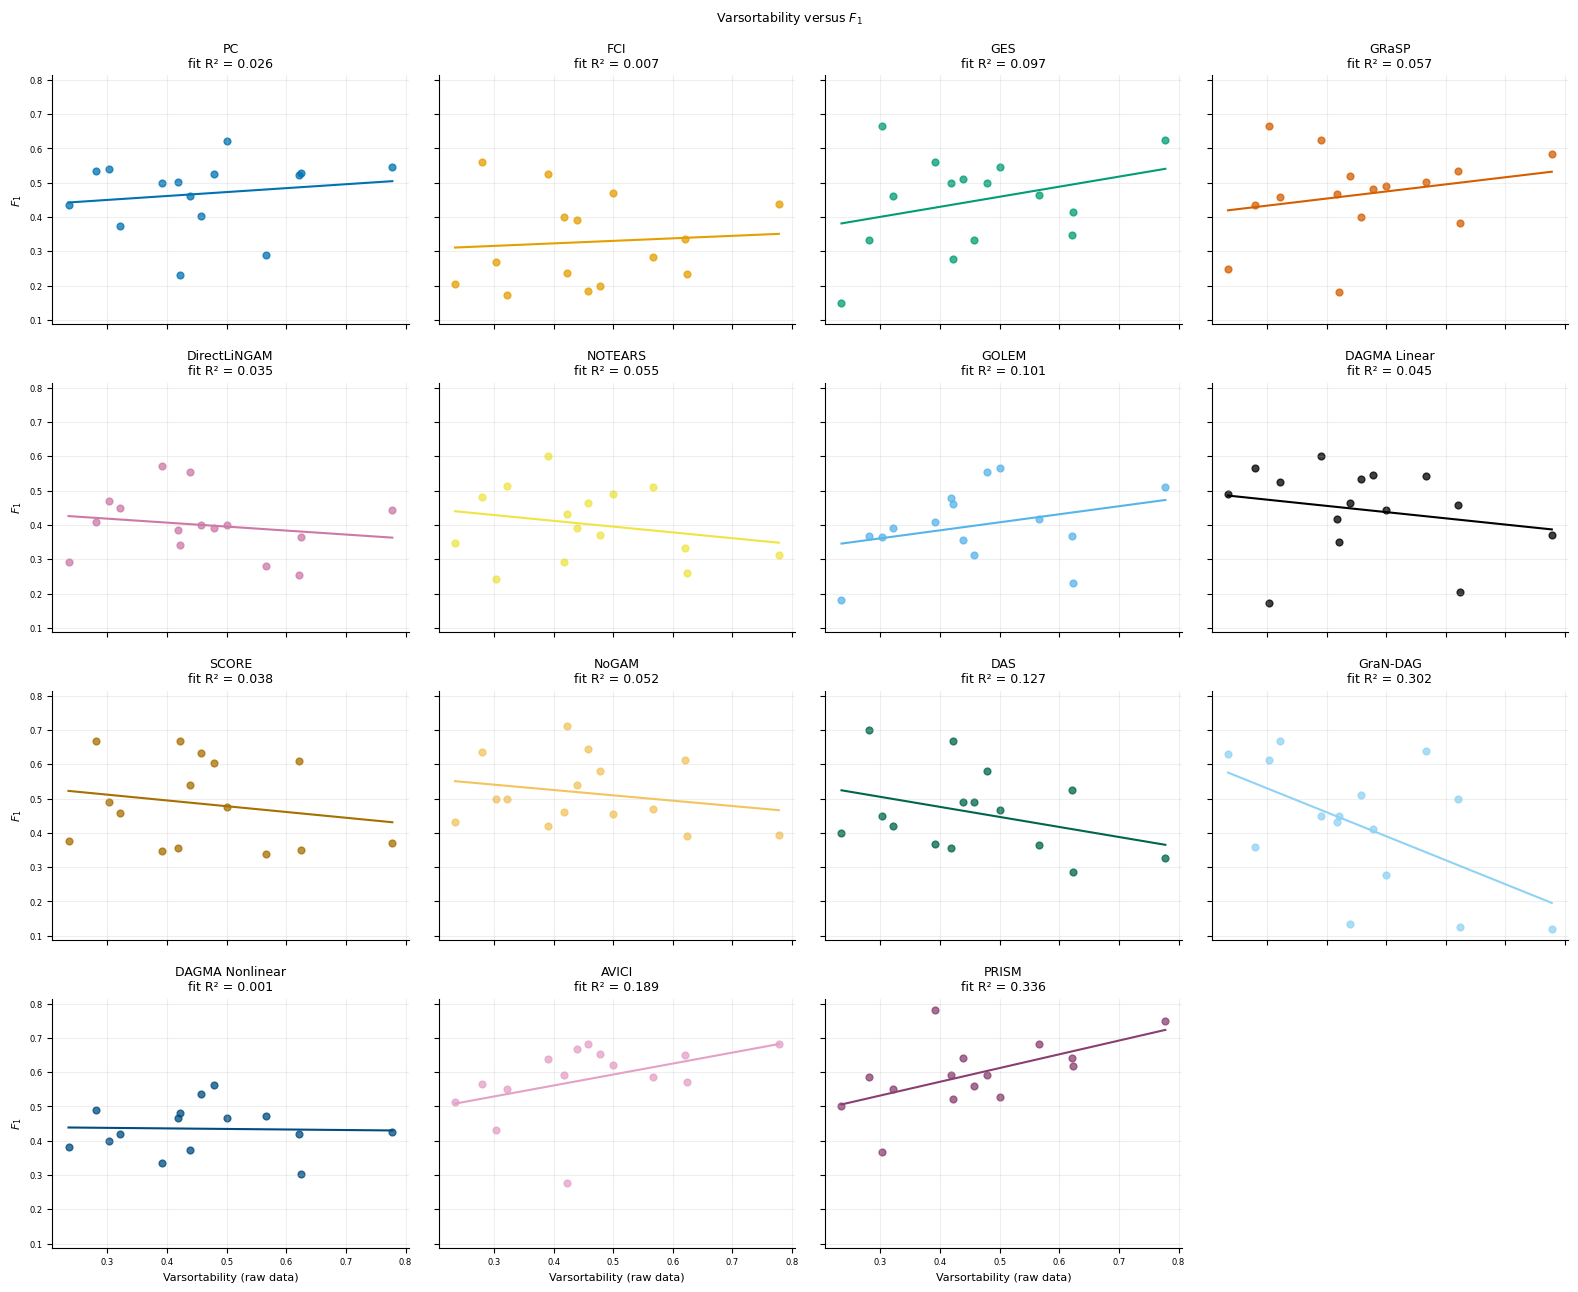

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,0.666667,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,0.465116,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
2,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,0.373396,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
3,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,0.489796,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
4,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,0.553191,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
5,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,0.390354,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
6,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,0.511628,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
7,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,0.355556,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
8,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,0.520930,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
9,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,0.133333,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,19,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,47,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.321739,0.139130,115,37,0,16,0,20,2000
2,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,50,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.280000,0.250000,100,28,0,25,0,20,2000
3,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,52,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.500000,0.482143,56,28,0,27,0,20,2000
4,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,71,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.478261,0.217391,46,22,0,10,0,20,2000
5,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,75,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.391304,0.434783,92,36,0,40,0,20,2000
6,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,77,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.457143,0.542857,70,32,0,38,0,20,2000
7,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,102,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.620690,0.275862,58,36,0,16,0,20,2000
8,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,125,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.566038,0.320755,53,30,0,17,0,20,2000
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,158,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.417910,0.253731,67,28,0,17,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.434878,0.189119,0.319879,0.433138,0.105236,0.589286,0.020794
1,DAGMA_Linear,15,-0.211365,0.044675,-0.181702,0.528363,0.449529,-0.257143,0.354860
2,DAGMA_Nonlinear,15,-0.032787,0.001075,-0.015878,0.442408,0.907654,0.035714,0.899447
3,DAS,15,-0.356793,0.127302,-0.292543,0.592743,0.191741,-0.267857,0.334444
4,DirectLiNGAM,15,-0.187962,0.035330,-0.115760,0.453128,0.502324,-0.310992,0.259219
5,FCI,15,0.083474,0.006968,0.073368,0.294000,0.767411,0.039286,0.889446
6,GES,15,0.311747,0.097186,0.292982,0.312814,0.258003,0.209303,0.454066
7,GOLEM,15,0.318404,0.101381,0.234018,0.290845,0.247432,0.309205,0.262112
8,GRaSP,15,0.238108,0.056696,0.207198,0.371073,0.392786,0.200000,0.474814
9,GraNDAG,15,-0.549674,0.302141,-0.699603,0.739997,0.033782,-0.461126,0.083621


,model,mean,std,size
0,AVICI,0.582960,0.096092,15
1,DAGMA_Linear,0.277409,0.107364,15
2,DAGMA_Nonlinear,0.345433,0.067832,15
3,DAS,0.452369,0.108788,15
4,DirectLiNGAM,0.386077,0.075246,15
5,FCI,0.235366,0.149056,15
6,GES,0.498584,0.092117,15
7,GOLEM,0.230769,0.085533,15
8,GRaSP,0.465459,0.127769,15
9,GraNDAG,0.101356,0.121206,15


,model,mean,std,size
0,AVICI,17.933333,3.954503,15
1,DAGMA_Linear,23.333333,3.039424,15
2,DAGMA_Nonlinear,23.506667,3.938721,15
3,DAS,29.733333,9.098404,15
4,DirectLiNGAM,30.666667,6.693992,15
5,FCI,31.080000,4.891275,15
6,GES,25.666667,4.402380,15
7,GOLEM,29.600000,5.315745,15
8,GRaSP,22.426667,4.653642,15
9,GraNDAG,25.000000,2.853569,15


,model,mean,std,size
0,AVICI,0.656225,0.132437,15
1,DAGMA_Linear,0.400690,0.164916,15
2,DAGMA_Nonlinear,0.430327,0.071434,15
3,DAS,0.388962,0.114984,15
4,DirectLiNGAM,0.333472,0.077915,15
5,FCI,0.626948,0.278174,15
6,GES,0.486661,0.072953,15
7,GOLEM,0.280694,0.108694,15
8,GRaSP,0.609458,0.157124,15
9,GraNDAG,0.420000,0.387718,15


,model,mean,std,size
0,AVICI,0.536318,0.108813,15
1,DAGMA_Linear,0.215912,0.087009,15
2,DAGMA_Nonlinear,0.296310,0.075920,15
3,DAS,0.553462,0.112651,15
4,DirectLiNGAM,0.471444,0.106499,15
5,FCI,0.157261,0.125549,15
6,GES,0.521870,0.133020,15
7,GOLEM,0.203944,0.084098,15
8,GRaSP,0.390830,0.129822,15
9,GraNDAG,0.060905,0.078351,15


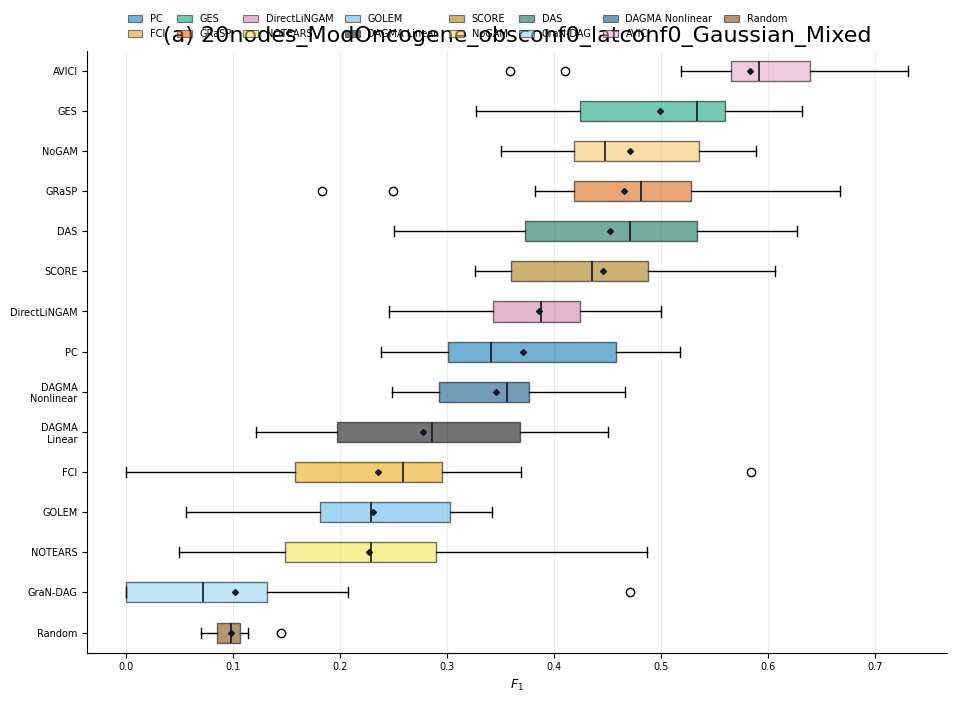

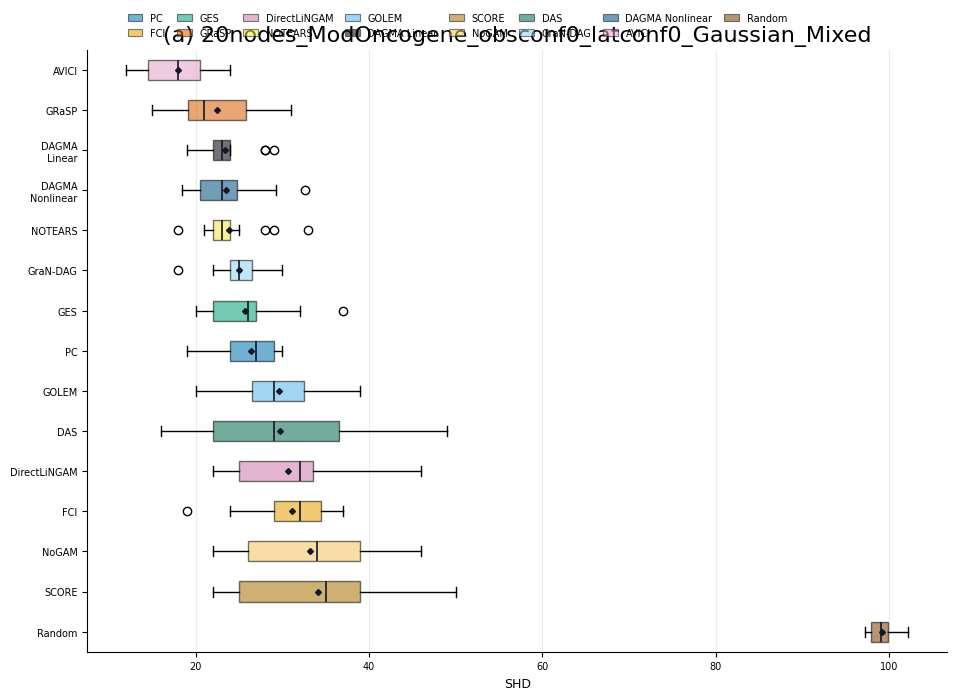

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.136910
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.000000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.186047
9,19,GraNDAG,0.000000


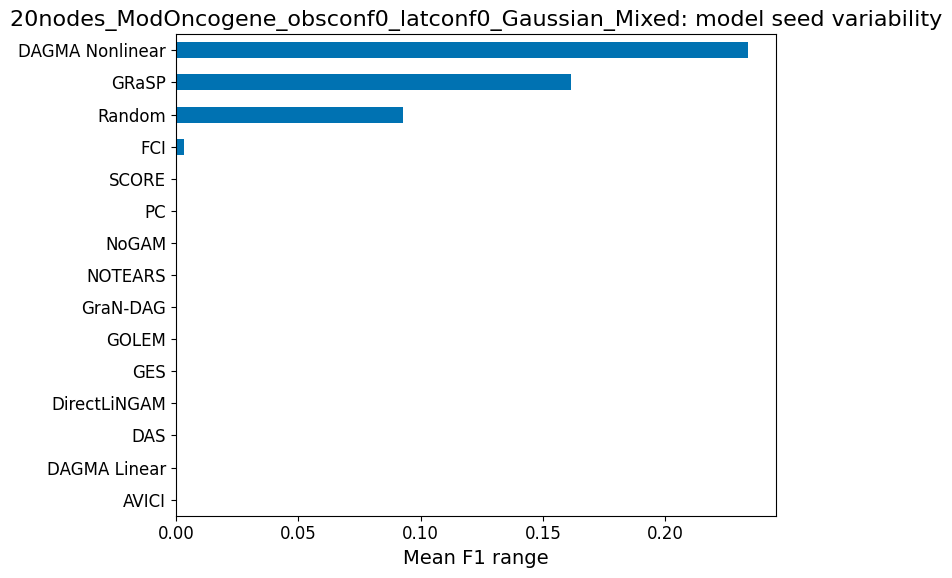

,model_seed,model,f1_range
0,0,AVICI,0.371795
1,0,DAGMA_Linear,0.328788
2,0,DAGMA_Nonlinear,0.337650
3,0,DAS,0.376866
4,0,DirectLiNGAM,0.254386
5,0,FCI,0.583333
6,0,GES,0.305048
7,0,GOLEM,0.285908
8,0,GRaSP,0.571429
9,0,GraNDAG,0.470588


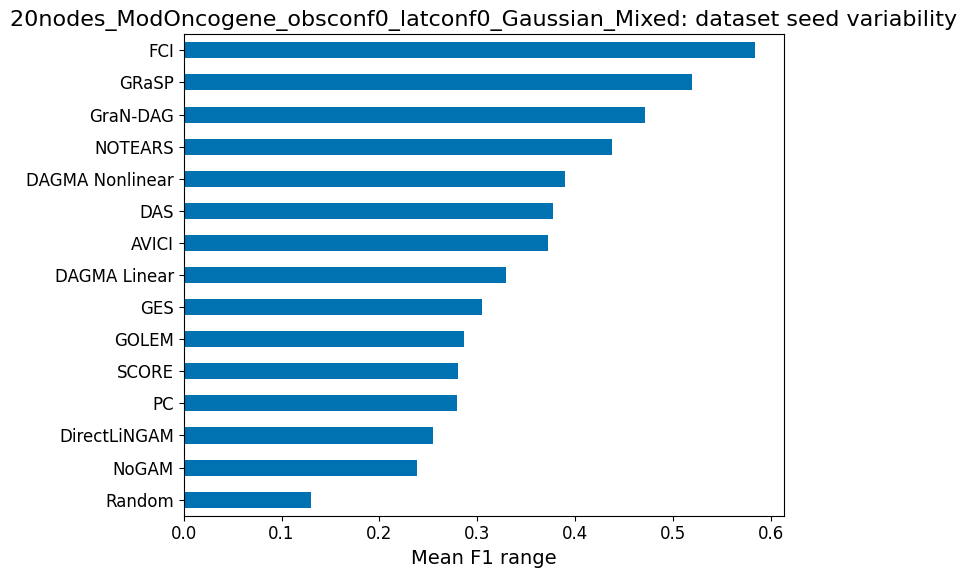

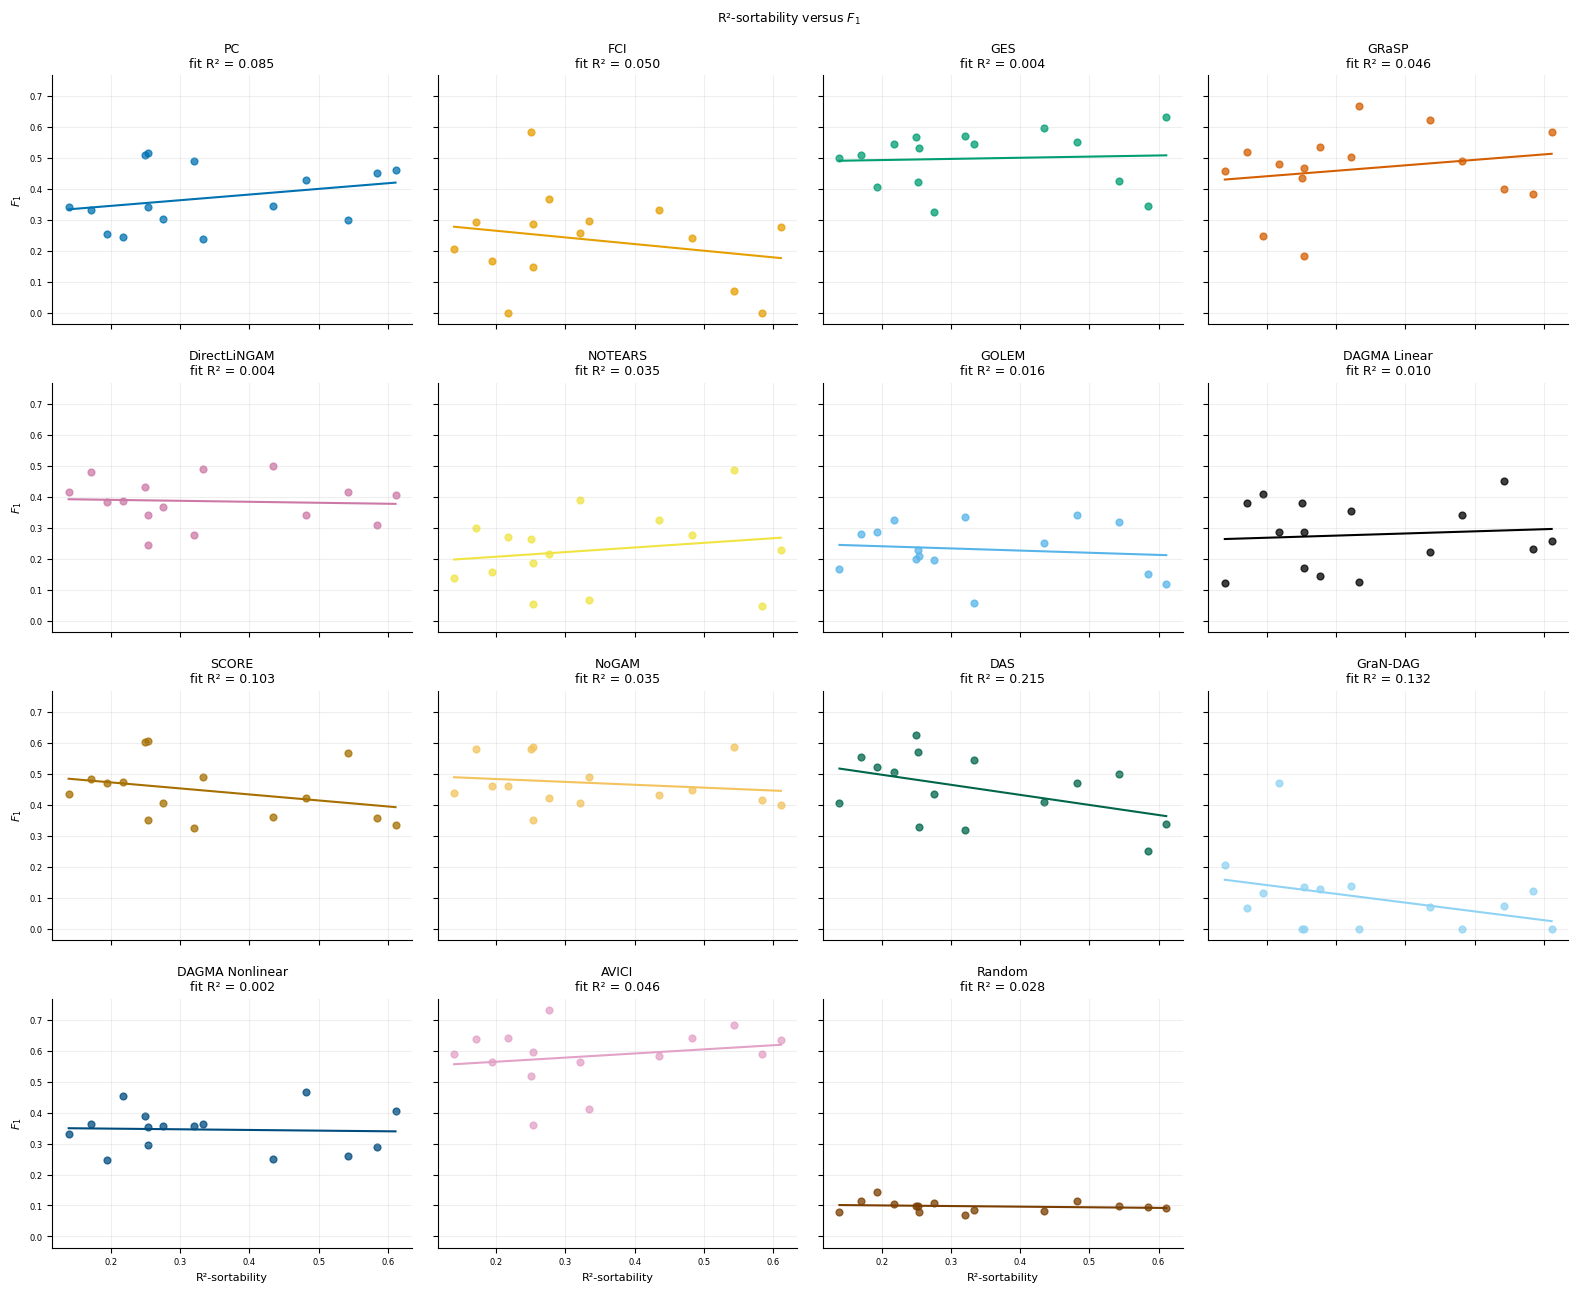

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,0.638298,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,0.380952,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
2,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,0.362376,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
3,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,0.555556,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
4,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,0.481481,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
5,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,0.294118,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
6,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,0.509804,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
7,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,0.280702,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
8,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,0.520930,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
9,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,0.066667,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,19,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,47,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.321739,0.139130,115,37,0,16,0,20,2000
2,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,50,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.280000,0.250000,100,28,0,25,0,20,2000
3,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,52,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.500000,0.482143,56,28,0,27,0,20,2000
4,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,71,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.478261,0.217391,46,22,0,10,0,20,2000
5,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,75,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.391304,0.434783,92,36,0,40,0,20,2000
6,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,77,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.457143,0.542857,70,32,0,38,0,20,2000
7,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,102,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.620690,0.275862,58,36,0,16,0,20,2000
8,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,125,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.566038,0.320755,53,30,0,17,0,20,2000
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,158,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.417910,0.253731,67,28,0,17,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.214833,0.046153,0.133178,0.538009,0.441949,0.171582,0.540905
1,DAGMA_Linear,15,0.099385,0.009877,0.068838,0.254174,0.724539,-0.041108,0.884348
2,DAGMA_Nonlinear,15,-0.049152,0.002416,-0.021509,0.352693,0.861902,0.032143,0.909462
3,DAS,15,-0.463923,0.215225,-0.325593,0.562265,0.081520,-0.460714,0.083933
4,DirectLiNGAM,15,-0.065180,0.004248,-0.031640,0.396756,0.817482,-0.132261,0.638442
5,FCI,15,-0.223379,0.049898,-0.214802,0.307867,0.423550,-0.057194,0.839558
6,GES,15,0.062393,0.003893,0.037078,0.486069,0.825173,0.253798,0.361372
7,GOLEM,15,-0.126772,0.016071,-0.069953,0.254380,0.652555,-0.146429,0.602550
8,GRaSP,15,0.214127,0.045850,0.176499,0.405886,0.443488,0.260714,0.347979
9,GraNDAG,15,-0.362644,0.131510,-0.283563,0.197066,0.184036,-0.370970,0.173422


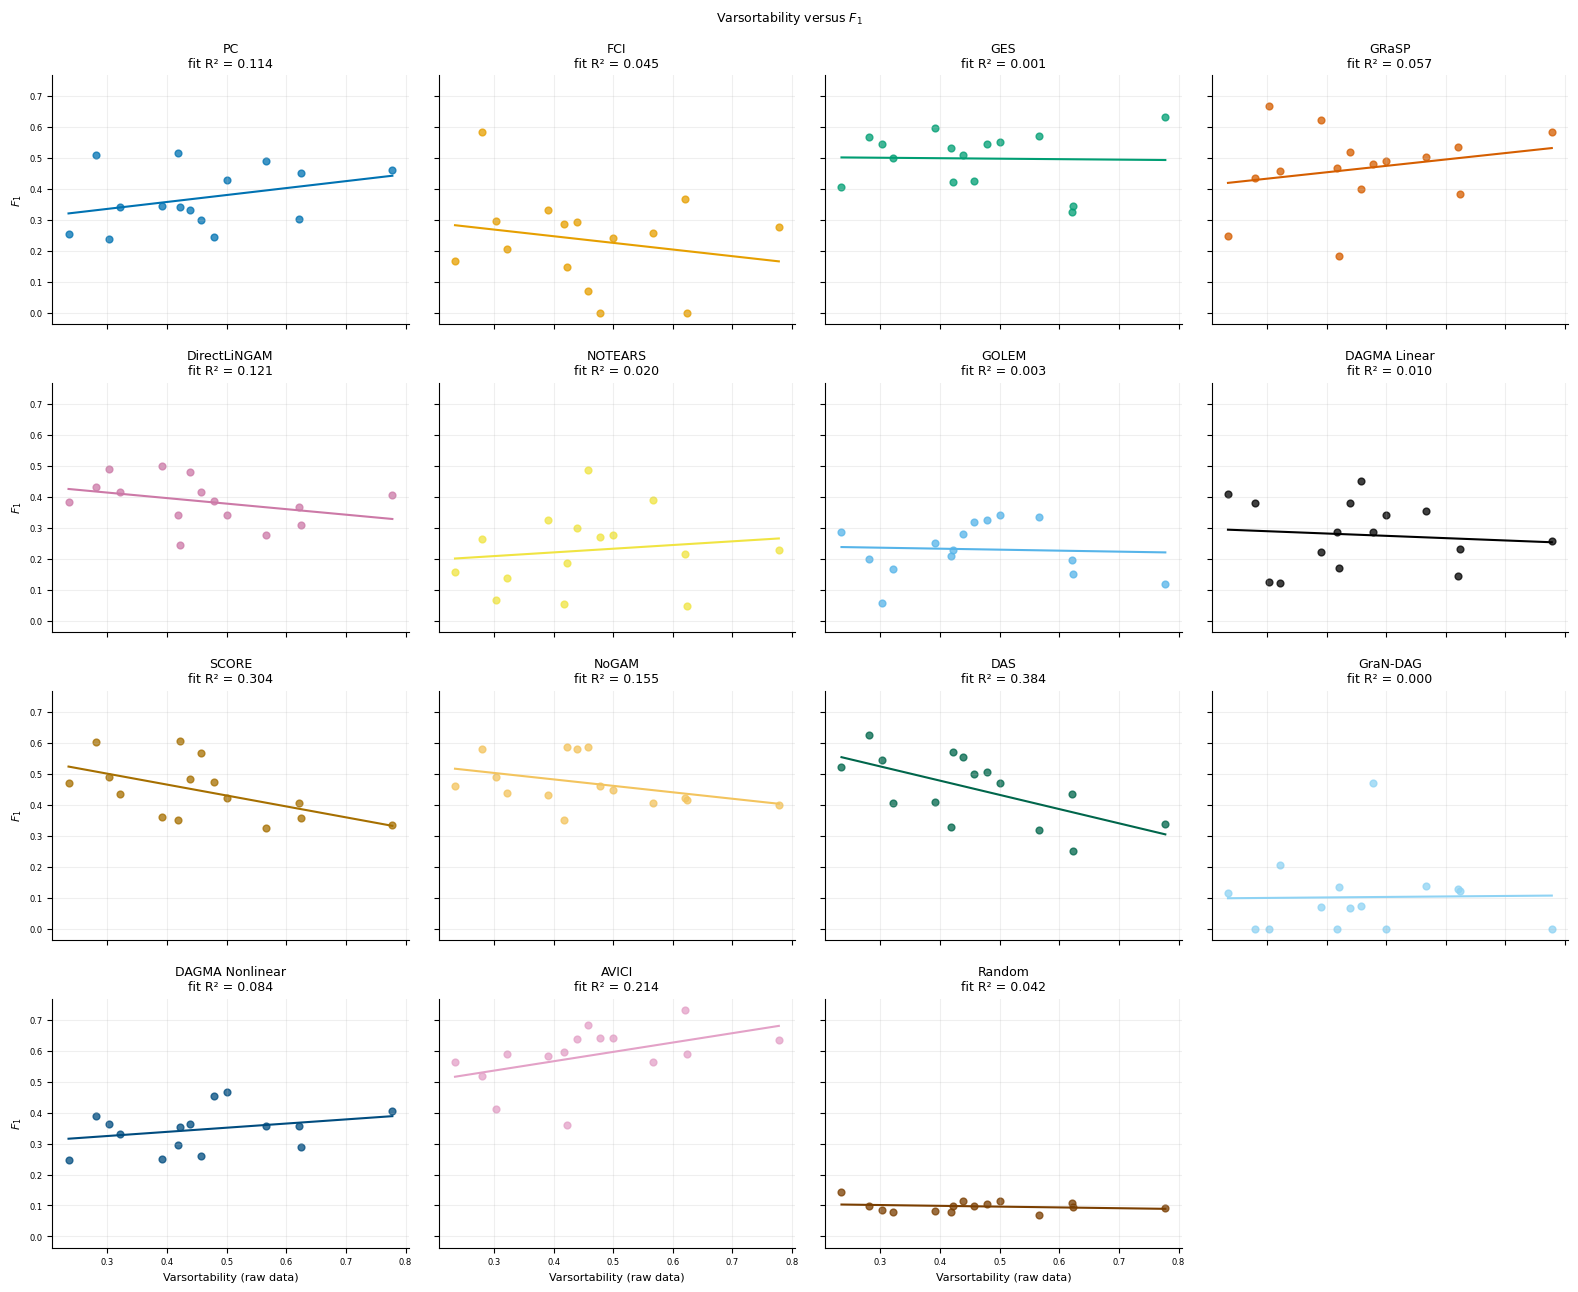

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,0.638298,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,0.380952,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
2,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,0.362376,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
3,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,0.555556,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
4,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,0.481481,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
5,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,0.294118,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
6,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,0.509804,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
7,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,0.280702,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
8,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,0.520930,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
9,19,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,0.066667,5,20,ModOncogene,0,0,Gaussian,...,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,19,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.439024,0.170732,41,18,0,7,0,20,2000
1,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,47,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.321739,0.139130,115,37,0,16,0,20,2000
2,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,50,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.280000,0.250000,100,28,0,25,0,20,2000
3,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,52,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.500000,0.482143,56,28,0,27,0,20,2000
4,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,71,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.478261,0.217391,46,22,0,10,0,20,2000
5,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,75,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.391304,0.434783,92,36,0,40,0,20,2000
6,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,77,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.457143,0.542857,70,32,0,38,0,20,2000
7,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,102,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.620690,0.275862,58,36,0,16,0,20,2000
8,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,125,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.566038,0.320755,53,30,0,17,0,20,2000
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,158,tuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.417910,0.253731,67,28,0,17,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.462429,0.213841,0.302633,0.445099,0.082637,0.548704,0.034162
1,DAGMA_Linear,15,-0.102350,0.010476,-0.074840,0.311501,0.716629,-0.050045,0.859417
2,DAGMA_Nonlinear,15,0.290578,0.084436,0.134240,0.284281,0.293415,0.307143,0.265473
3,DAS,15,-0.620004,0.384406,-0.459371,0.661630,0.013679,-0.553571,0.032287
4,DirectLiNGAM,15,-0.348440,0.121411,-0.178565,0.467420,0.203098,-0.470063,0.077042
5,FCI,15,-0.211954,0.044924,-0.215168,0.333383,0.448237,-0.253798,0.361372
6,GES,15,-0.024599,0.000605,-0.015432,0.505614,0.930658,0.016086,0.954626
7,GOLEM,15,-0.054670,0.002989,-0.031847,0.245277,0.846560,0.046429,0.869492
8,GRaSP,15,0.238108,0.056696,0.207198,0.371073,0.392786,0.200000,0.474814
9,GraNDAG,15,0.019203,0.000369,0.015852,0.094135,0.945843,0.160026,0.568879


In [3]:
for study, frame in [("tuned", complete)]:
    frame = frame.loc[frame.dataset.eq('20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,r2_sortability,15,0.335714,0.221212,estimated,1.000000
1,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,r2_sortability,15,-0.321429,0.242719,estimated,1.000000
2,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,r2_sortability,15,-0.089286,0.751673,estimated,1.000000
3,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,r2_sortability,15,-0.432143,0.107693,estimated,1.000000
4,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,r2_sortability,15,0.005362,0.984869,estimated,1.000000
5,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,r2_sortability,15,0.260714,0.347979,estimated,1.000000
6,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,r2_sortability,15,0.338104,0.217735,estimated,1.000000
7,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,r2_sortability,15,0.109026,0.698919,estimated,1.000000
8,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,r2_sortability,15,0.260714,0.347979,estimated,1.000000
9,tuned,tuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,r2_sortability,15,-0.348526,0.202980,estimated,1.000000
